# Loan Approval Prediction
**Elevvo Machine Learning Internship, Level 2, Task 1**

**Goal:** predict whether a loan application is approved, and evaluate the models properly on **imbalanced data** using precision, recall and F1 of the *Approved* class (accuracy alone would be misleading).

## Dataset properties (`loan_data.csv`)

| Property | Value |
|---|---|
| Rows x columns | 24,000 x 7 |
| Target | `Approval` (`Approved` / `Rejected`) |
| Class balance | about 83.6% Rejected / 16.4% Approved (roughly 5 : 1) |
| Numeric features | `Income`, `Credit_Score`, `Loan_Amount`, `DTI_Ratio` |
| Categorical feature | `Employment_Status` |
| Free-text feature | `Text` (the applicant's stated loan purpose) |

**Engineering decisions driven by these properties**
- **Imbalance (5 : 1):** stratified splits, F1 / PR-AUC of the Approved class as headline metrics, a dummy baseline as a reality check, and a comparison of class weights and SMOTE.
- **Free text:** one-hot encoding it would create thousands of useless columns, so it is converted with TF-IDF **inside** the pipeline. Because it may add nothing, a **feature-set ablation** decides whether it earns a place in the final model.
- **Skewed `Loan_Amount` / `DTI_Ratio`:** tree models handle skew natively. For the linear model we also test a `loan_to_income` ratio feature.

## Plan
1. Configuration, load and validate the data
2. Exploratory data analysis (EDA)
3. Stratified train/test split
4. Which inputs are worth using? Feature-set ablation
5. Model comparison: Logistic Regression vs Decision Tree vs Gradient Boosting, with class weights and SMOTE
6. Hyperparameter tuning and tree complexity
7. Final evaluation on the untouched test set
8. Decision threshold tuning (business objective)
9. Error analysis, feature importance, stress test
10. Save results, conclusions and limitations

**How to run:** set `DATA_PATH` in the configuration cell, then use *Restart and Run All*. Figures are saved to `images/` and tables to `results/`.

In [1]:
import re
import warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             precision_recall_curve, average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)
from sklearn.inspection import permutation_importance

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.1.1 | scikit-learn 1.9.1


In [2]:
# SMOTE lives in imbalanced-learn. Its Pipeline applies SMOTE ONLY when fitting (never to validation/test data).
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
except ImportError:
    %pip install imbalanced-learn
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

## 0. Configuration

In [3]:
RANDOM_STATE = 42
DATA_PATH = "D:/Freelance/Elevvo Internship/Tasks/Loan Approval Prediction Description/loan_data.csv"   

IMG_DIR = Path("images");  IMG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

def save_fig(name):
    """Save the current figure so the README can use real image files."""
    plt.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

def slug(text):
    return re.sub(r"\W+", "_", text.lower()).strip("_")

## 1. Load, clean and validate

Column names are normalised to `lower_snake_case` and string values are stripped of stray whitespace. Then the schema is **asserted**, so the notebook fails early with a clear message if the file is not the expected dataset.

In [4]:
df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].str.strip()

print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
df.head()

Shape: (24000, 7)
Duplicate rows: 0


,text,income,credit_score,loan_amount,dti_ratio,employment_status,approval
0,I need a loan to pay for an international vacation with my family.,26556,581,8314,79.26,employed,Rejected
1,I want to make home improvements like installing solar panels.,197392,389,111604,22.14,employed,Rejected
2,"I need a loan for home renovation, including a kitchen remodel.",44561,523,34118,45.44,employed,Rejected
3,I need funds to buy new furniture and appliances for my house.,190363,729,118757,10.22,unemployed,Rejected
4,I need a loan to start a small business.,61853,732,19210,44.13,employed,Approved


In [5]:
# ---- Schema ----
TARGET     = "approval"
BASE_NUM   = ["income", "credit_score", "loan_amount", "dti_ratio"]
CAT_COLS   = ["employment_status"]
TEXT_COL   = "text"

missing_cols = set(BASE_NUM + CAT_COLS + [TEXT_COL, TARGET]) - set(df.columns)
assert not missing_cols, f"Unexpected file: missing columns {missing_cols}. Found: {df.columns.tolist()}"

# ---- Target: Approved = 1 ----
labels = df[TARGET].astype(str).str.strip().str.lower()
assert set(labels.unique()) <= {"approved", "rejected"}, f"Unexpected target values: {labels.unique()}"
y = (labels == "approved").astype(int)

# ---- Features ----
df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
df["loan_to_income"] = (df["loan_amount"] / df["income"]).replace([np.inf, -np.inf], np.nan)   # engineered candidate
X = df[BASE_NUM + ["loan_to_income"] + CAT_COLS + [TEXT_COL]].copy()

print("Target counts:\n", labels.value_counts())
print("\nApproved share:", y.mean().round(3))
print("Features:", X.columns.tolist())

Target counts:
 approval
rejected    20067
approved     3933
Name: count, dtype: int64

Approved share: 0.164
Features: ['income', 'credit_score', 'loan_amount', 'dti_ratio', 'loan_to_income', 'employment_status', 'text']


In [6]:
# ---- Data-quality checks ----
print(df[BASE_NUM].describe().round(2))
print()
print("Credit scores outside 300-850 :", int(((df.credit_score < 300) | (df.credit_score > 850)).sum()))
print("Non-positive income           :", int((df.income <= 0).sum()))
print("DTI ratio above 100%          :", int((df.dti_ratio > 100).sum()), f"({(df.dti_ratio > 100).mean():.1%})")
print("Unique loan-purpose texts     :", df[TEXT_COL].nunique(), "of", len(df))
print("Empty texts                   :", int((df[TEXT_COL].str.len() == 0).sum()))
print()
miss = X.isna().sum()
print("Missing values per feature:")
print(miss[miss > 0] if miss.any() else "None")

          income  credit_score  loan_amount  dti_ratio
count   24000.00      24000.00     24000.00   24000.00
mean   110377.55        575.72     44356.15      34.72
std     51729.68        159.23     34666.60      32.32
min     20001.00        300.00      1005.00       2.53
25%     65635.75        437.00     16212.00      14.51
50%    110464.00        575.00     35207.00      24.86
75%    155187.00        715.00     65622.75      41.84
max    200000.00        850.00    158834.00     246.33

Credit scores outside 300-850 : 0
Non-positive income           : 0
DTI ratio above 100%          : 1255 (5.2%)
Unique loan-purpose texts     : 70 of 24000
Empty texts                   : 0

Missing values per feature:
None


## 2. Exploratory data analysis

Questions to answer:
- How imbalanced is the target, and what accuracy would a model that always says "Rejected" get?
- Are there missing values or implausible values (for example DTI above 100%)?
- Which features separate Approved from Rejected, and is the relationship **linear** (credit score rising smoothly) or **threshold-like**? The answer predicts whether a tree or a linear model will win.
- Does the free-text purpose differ between approved and rejected applications?

          count  share
approval              
Rejected  20067  0.836
Approved   3933  0.164

Accuracy of a model that always predicts 'Rejected': 0.836  <- why accuracy is not the headline metric


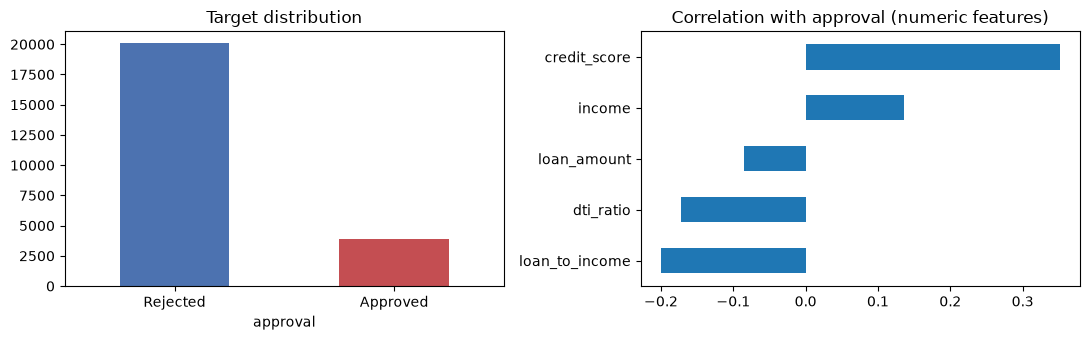

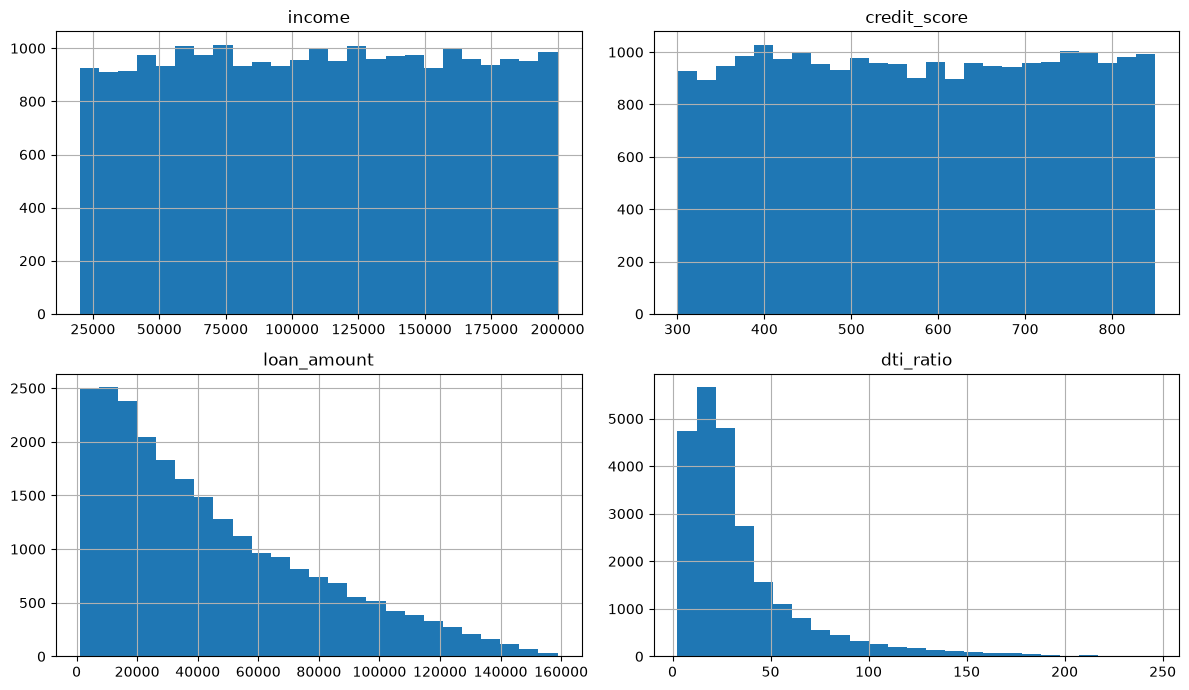

In [7]:
dist = y.value_counts().rename({1: "Approved", 0: "Rejected"})
print(pd.DataFrame({"count": dist, "share": (dist / len(y)).round(3)}))
print(f"\nAccuracy of a model that always predicts 'Rejected': {1 - y.mean():.3f}  <- why accuracy is not the headline metric")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
dist.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"]); axes[0].set_title("Target distribution")
axes[0].tick_params(axis="x", rotation=0)
X[BASE_NUM + ["loan_to_income"]].assign(target=y).corr()["target"].drop("target").sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Correlation with approval (numeric features)")
plt.tight_layout(); save_fig("eda_target_and_correlation"); plt.show()

X[BASE_NUM].hist(bins=25, figsize=(12, 7)); plt.tight_layout(); save_fig("eda_histograms"); plt.show()

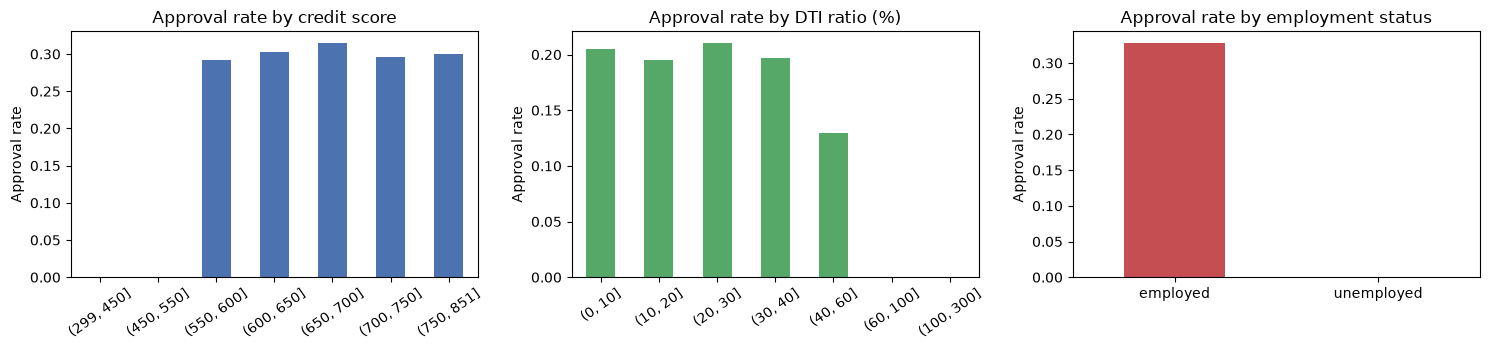

In [8]:
# Is the relationship linear or threshold-like? Approval rate by band.
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

y.groupby(pd.cut(X["credit_score"], bins=[299, 450, 550, 600, 650, 700, 750, 851])).mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Approval rate by credit score"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=35)

y.groupby(pd.cut(X["dti_ratio"], bins=[0, 10, 20, 30, 40, 60, 100, 300])).mean().plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Approval rate by DTI ratio (%)"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=35)

y.groupby(X["employment_status"]).mean().plot(kind="bar", ax=axes[2], color="#C44E52")
axes[2].set_title("Approval rate by employment status"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=0)

for ax in axes: ax.set_ylabel("Approval rate")
plt.tight_layout(); save_fig("eda_approval_rate_by_band"); plt.show()

In [9]:
# Do the hard eligibility rules really exist? (EDA only, nothing is hard-coded into the models)
approved = df[y == 1]
print("Approved applications          :", len(approved))
print("Unemployed among approved      :", int((approved["employment_status"] == "unemployed").sum()))
print("Min credit score among approved:", int(approved["credit_score"].min()))
print("Max DTI among approved         :", round(float(approved["dti_ratio"].max()), 1))
print("Max loan_to_income, approved   :", round(float(approved["loan_to_income"].max()), 3))
print("Min income among approved      :", int(approved["income"].min()))
print()
print(pd.crosstab(df["employment_status"], df[TARGET]))

Approved applications          : 3933
Unemployed among approved      : 0
Min credit score among approved: 551
Max DTI among approved         : 50.0
Max loan_to_income, approved   : 0.6
Min income among approved      : 20279

approval           Approved  Rejected
employment_status                    
employed               3933      8060
unemployed                0     12007


In [10]:
# Does an AND of the four discovered rules reproduce the labels? (EDA only, never fed to the models)
rule = ((df["employment_status"] == "employed") & (df["credit_score"] > 550)
        & (df["dti_ratio"] <= 50) & (df["loan_to_income"] <= 0.6))

print(pd.crosstab(rule.rename("meets all 4 rules"), df[TARGET]))
print("\nRule precision:", round(precision_score(y, rule.astype(int)), 4),
      "| recall:", round(recall_score(y, rule.astype(int)), 4))

approval           Approved  Rejected
meets all 4 rules                    
False                     0     20067
True                   3933         0

Rule precision: 1.0 | recall: 1.0


In [11]:
# The free-text column: what does it look like, and does it differ by class?
for label, name in [(1, "Approved"), (0, "Rejected")]:
    print(f"--- 3 random {name} examples ---")
    for t in df.loc[y == label, TEXT_COL].sample(3, random_state=RANDOM_STATE):
        print("  *", t[:160])

lengths = df[TEXT_COL].str.split().str.len()
print("\nWord count by class:")
print(lengths.groupby(y.map({1: "Approved", 0: "Rejected"})).describe().round(1))

--- 3 random Approved examples ---
  * I need financial help to cover maternity and delivery expenses.
  * I need a loan to pay for legal fees related to my business license.
  * I need a loan to buy a reliable used car for work commuting.
--- 3 random Rejected examples ---
  * I need a loan to finance my MBA and career advancement.
  * I need a loan to buy a truck and start a moving business.
  * I need money to purchase updated equipment for my photography business.

Word count by class:
            count  mean  std  min   25%   50%   75%   max
approval                                                 
Approved   3933.0  11.8  1.6  8.0  11.0  12.0  13.0  15.0
Rejected  20067.0  11.8  1.6  8.0  11.0  12.0  13.0  15.0


**My EDA notes** (fill in after running):
- Class balance: ...
- Data-quality issues (DTI above 100%, uniform distributions that suggest synthetic data, missing values): ...
- Strongest signals and whether they look linear or threshold-like: ...
- Text column: ...

## 3. Train/test split and cross-validation setup

The split is **stratified**, so train and test keep the same 16.4% approval rate. The test set stays untouched until Section 7. Every choice before that (features, models, hyperparameters, threshold) is made with cross-validation on the training data only.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(X_train.shape, X_test.shape)
print("Approved share  train:", y_train.mean().round(3), " test:", y_test.mean().round(3))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}

(19200, 7) (4800, 7)
Approved share  train: 0.164  test: 0.164


## 4. Which inputs are worth using? Feature-set ablation

Three candidate additions to the four base numeric features and employment status:

| Feature set | Contents |
|---|---|
| `tabular` | income, credit score, loan amount, DTI, employment status |
| `tabular + loan_to_income` | the above plus `loan_amount / income` |
| `tabular + text` | the tabular features plus 300 TF-IDF features from `Text` |
| `text only` | diagnostic: how much signal does the text hold on its own? |

Two probe models are used (a linear and a tree model) because features help models differently. **Rule:** a richer feature set is adopted only if it improves the probes' average CV F1 by more than `MIN_GAIN`; otherwise the simpler `tabular` set is kept. Everything (imputation, scaling, encoding, TF-IDF) is fitted **inside** the pipeline, so cross-validation has no leakage.

In [13]:
def make_preprocessor(fs):
    """Build the ColumnTransformer for a feature set fs = {'num': [...], 'cat': [...], 'text': col or None}."""
    parts = []
    if fs["num"]:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), fs["num"]))
    if fs["cat"]:
        parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                       ("oh", OneHotEncoder(handle_unknown="ignore"))]), fs["cat"]))
    if fs["text"]:   
        parts.append(("txt", TfidfVectorizer(max_features=300, ngram_range=(1, 2),
                                             stop_words="english", min_df=5), fs["text"]))
    return ColumnTransformer(parts, sparse_threshold=0)  

def build(model, fs, smote=False):
    steps = [("prep", make_preprocessor(fs))]
    if smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

LR  = lambda **kw: LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **kw)
DT  = lambda **kw: DecisionTreeClassifier(random_state=RANDOM_STATE, **kw)
HGB = lambda **kw: HistGradientBoostingClassifier(random_state=RANDOM_STATE, **kw)

FEATURE_SETS = {
    "tabular":                  {"num": BASE_NUM,                      "cat": CAT_COLS, "text": None},
    "tabular + loan_to_income": {"num": BASE_NUM + ["loan_to_income"], "cat": CAT_COLS, "text": None},
    "tabular + text":           {"num": BASE_NUM,                      "cat": CAT_COLS, "text": TEXT_COL},
    "text only":                {"num": [],                            "cat": [],       "text": TEXT_COL},
}

In [14]:
probe_models = {
    "LogReg (balanced)": lambda fs: build(LR(class_weight="balanced"), fs),
    "Tree (depth 8)":    lambda fs: build(DT(max_depth=8, min_samples_leaf=10), fs),
}

rows = []
for fs_name, fs in FEATURE_SETS.items():
    for m_name, make in probe_models.items():
        s = cross_validate(make(fs), X_train, y_train, cv=cv, n_jobs=-1,
                           scoring={"f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"})
        rows.append({"feature_set": fs_name, "model": m_name,
                     "f1": s["test_f1"].mean(), "pr_auc": s["test_pr_auc"].mean(), "roc_auc": s["test_roc_auc"].mean()})

ablation = pd.DataFrame(rows)
ablation.pivot(index="feature_set", columns="model", values=["f1", "pr_auc", "roc_auc"]).round(3)

f1                           pr_auc  \
model                    LogReg (balanced) Tree (depth 8) LogReg (balanced)   
feature_set                                                                   
tabular                              0.771          0.972             0.885   
tabular + loan_to_income             0.781          1.000             0.891   
tabular + text                       0.770          0.972             0.882   
text only                            0.249          0.000             0.167   

                                                  roc_auc                 
model                    Tree (depth 8) LogReg (balanced) Tree (depth 8)  
feature_set                                                               
tabular                           0.988             0.976          0.997  
tabular + loan_to_income          1.000             0.977          1.000  
tabular + text                    0.987             0.975          0.997  
text only                         0.165             0.505          0.500

In [15]:
MIN_GAIN = 0.005                 # required average-F1 improvement to justify extra complexity
FORCE_FEATURE_SET = None         # or one of the FEATURE_SETS keys to override the automatic choice

mean_f1 = ablation.groupby("feature_set")["f1"].mean().drop("text only")
best_name = mean_f1.idxmax()
auto_choice = best_name if (mean_f1[best_name] - mean_f1["tabular"]) > MIN_GAIN else "tabular"

FEATURE_SET = FORCE_FEATURE_SET or auto_choice
FS = FEATURE_SETS[FEATURE_SET]
USED_COLS = FS["num"] + FS["cat"] + ([FS["text"]] if FS["text"] else [])

print("Mean probe F1 per feature set:\n", mean_f1.round(4).to_string())
print(f"\n>>> Selected feature set: '{FEATURE_SET}'")
print("Columns used:", USED_COLS)

Mean probe F1 per feature set:
 feature_set
tabular                     0.8717
tabular + loan_to_income    0.8903
tabular + text              0.8712

>>> Selected feature set: 'tabular + loan_to_income'
Columns used: ['income', 'credit_score', 'loan_amount', 'dti_ratio', 'loan_to_income', 'employment_status']


**Read the ablation:**
- If `text only` scores near ROC-AUC 0.5, the loan-purpose text carries no usable signal on its own, which is a legitimate finding.
- If `text only` is strong, check whether the text was generated differently for approved and rejected cases (leakage) before celebrating.
- If `loan_to_income` lifts the *linear* model but not the tree, that tells you the tree was already learning the interaction by itself.

Everything below uses the selected feature set `FS`.

## 5. Model comparison (cross-validation on the training data)

Eight variants are compared with 5-fold stratified CV. All metrics are for the **Approved** class, plus ROC-AUC and PR-AUC.

- **Dummy** is the reality check: it learns nothing, and PR-AUC equals the approval rate.
- **Class weights vs SMOTE** are the two imbalance techniques requested by the task.
- **HistGradientBoosting** is included because boosted trees give smoother probabilities than a single tree, which matters for threshold tuning later.

In [16]:
experiments = {
    "Dummy (always majority)": build(DummyClassifier(strategy="most_frequent"), FS),
    "LogReg":                  build(LR(), FS),
    "LogReg + class_weight":   build(LR(class_weight="balanced"), FS),
    "LogReg + SMOTE":          build(LR(), FS, smote=True),
    "Tree":                    build(DT(), FS),
    "Tree + class_weight":     build(DT(class_weight="balanced"), FS),
    "Tree + SMOTE":            build(DT(), FS, smote=True),
    "HistGB":                  build(HGB(), FS),
}

rows = []
for name, pipe in experiments.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{k: s[f"test_{k}"].mean() for k in scoring}})

cv_table = pd.DataFrame(rows).set_index("model").round(3).sort_values("f1", ascending=False)
cv_table

,precision,recall,f1,roc_auc,pr_auc
model,,,,,
Tree + class_weight,1.000,1.000,1.000,1.000,1.000
Tree + SMOTE,1.000,1.000,1.000,1.000,1.000
Tree,1.000,1.000,1.000,1.000,1.000
HistGB,0.997,0.997,0.997,1.000,0.999
LogReg,0.809,0.773,0.790,0.977,0.896
LogReg + SMOTE,0.665,0.949,0.782,0.977,0.891
LogReg + class_weight,0.662,0.951,0.781,0.977,0.891
Dummy (always majority),0.000,0.000,0.000,0.500,0.164


**Read the table:**
- Does SMOTE or class weighting improve **F1**, or does it only move the balance between precision and recall? (With a 5 : 1 imbalance, expect a trade-off for linear models and little change for trees.)
- How large is the gap between the linear and tree-based models, and what does it say about the structure of the data?
- Report what you see honestly, even if the answer is "no big difference".

## 6. Hyperparameter tuning and tree complexity

An unconstrained tree memorises its training data, so the grid limits depth and leaf size and selects by cross-validated F1. We then ask a second, more practical question: **how simple can the tree be** before it loses accuracy? A shallow tree can be read and explained to a credit officer, and a model nobody can explain is hard to deploy in banking.

In [17]:
param_grid = {
    "model__max_depth": [3, 4, 5, 6, 8, 10, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion": ["gini", "entropy"],
}
gs = GridSearchCV(build(DT(), FS), param_grid, scoring="f1", cv=cv, n_jobs=-1)
gs.fit(X_train, y_train)
print("Best params:", gs.best_params_)
print("Best CV F1:", round(gs.best_score_, 4))

Best params: {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 1}
Best CV F1: 0.9998


Best CV F1 by max_depth:
 3       0.8913
4       0.9998
5       0.9998
6       0.9998
8       0.9998
10      0.9998
None    0.9998


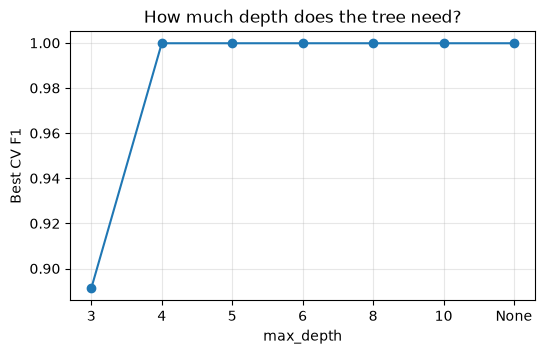


Simplest tree within 0.002 F1 of the best: depth=4, min_samples_leaf=20, criterion=gini, CV F1=0.9998


In [18]:
res = pd.DataFrame(gs.cv_results_)
res["depth"] = res["param_model__max_depth"].apply(lambda d: np.inf if (d is None or pd.isna(d)) else float(d))
res["leaf"] = res["param_model__min_samples_leaf"].astype(int)
res["criterion"] = res["param_model__criterion"].astype(str)

best_by_depth = res.groupby("depth")["mean_test_score"].max()
best_by_depth.index = ["None" if np.isinf(d) else str(int(d)) for d in best_by_depth.index]
print("Best CV F1 by max_depth:\n", best_by_depth.round(4).to_string())

plt.figure(figsize=(6, 3.5))
best_by_depth.plot(marker="o"); plt.xlabel("max_depth"); plt.ylabel("Best CV F1"); plt.title("How much depth does the tree need?")
plt.grid(alpha=0.3); save_fig("tree_depth_vs_f1"); plt.show()

# Simplest tree within TOL of the best CV F1 (shallowest, then largest leaves)
TOL = 0.002
eligible = res[res["mean_test_score"] >= gs.best_score_ - TOL].sort_values(
    ["depth", "leaf", "mean_test_score"], ascending=[True, False, False])
row = eligible.iloc[0]
simple_depth = None if np.isinf(row["depth"]) else int(row["depth"])
simple_tree = build(DT(criterion=row["criterion"], max_depth=simple_depth, min_samples_leaf=int(row["leaf"])), FS)
simple_tree.fit(X_train, y_train)
print(f"\nSimplest tree within {TOL} F1 of the best: depth={simple_depth}, min_samples_leaf={int(row['leaf'])}, "
      f"criterion={row['criterion']}, CV F1={row['mean_test_score']:.4f}")

## 7. Final evaluation on the held-out test set

Four finalists are evaluated **once**, at the default 0.5 threshold: the linear baseline, the tuned tree, the simplest near-equivalent tree, and gradient boosting. Never choose models by looking at test results; that is what Sections 4 to 6 are for.

===== LogReg + class_weight (threshold=0.500) =====
              precision    recall  f1-score   support

    Rejected      0.989     0.894     0.939      4013
    Approved      0.637     0.948     0.762       787

    accuracy                          0.903      4800
   macro avg      0.813     0.921     0.851      4800
weighted avg      0.931     0.903     0.910      4800



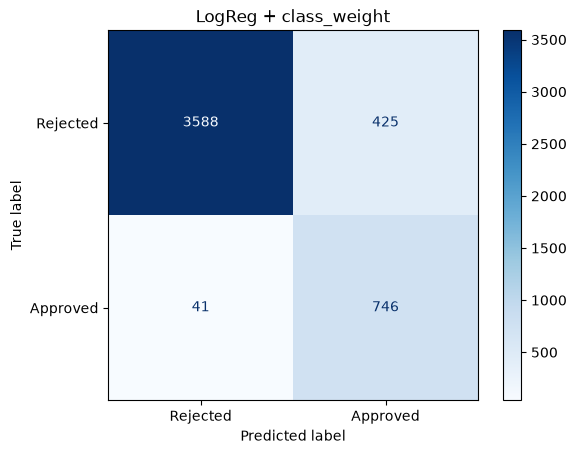

===== Decision Tree (tuned) (threshold=0.500) =====
              precision    recall  f1-score   support

    Rejected      1.000     1.000     1.000      4013
    Approved      0.999     1.000     0.999       787

    accuracy                          1.000      4800
   macro avg      0.999     1.000     1.000      4800
weighted avg      1.000     1.000     1.000      4800



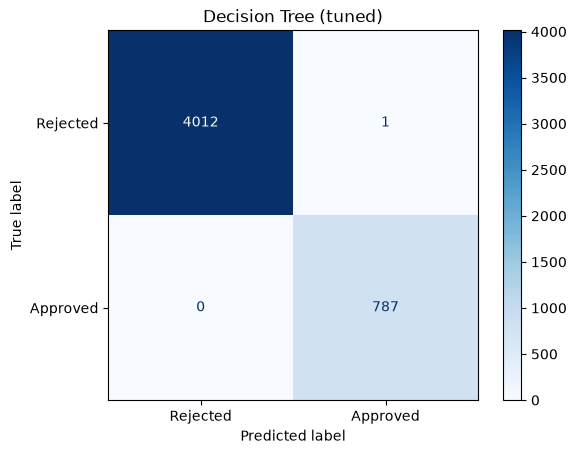

===== Decision Tree (simple) (threshold=0.500) =====
              precision    recall  f1-score   support

    Rejected      1.000     1.000     1.000      4013
    Approved      0.999     1.000     0.999       787

    accuracy                          1.000      4800
   macro avg      0.999     1.000     1.000      4800
weighted avg      1.000     1.000     1.000      4800



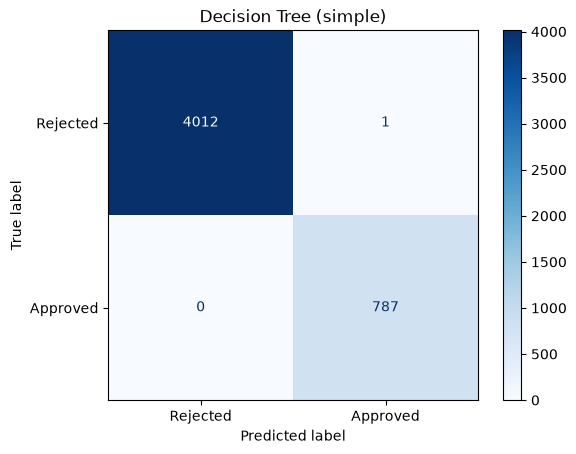

===== HistGB (threshold=0.500) =====
              precision    recall  f1-score   support

    Rejected      0.999     0.999     0.999      4013
    Approved      0.996     0.996     0.996       787

    accuracy                          0.999      4800
   macro avg      0.998     0.998     0.998      4800
weighted avg      0.999     0.999     0.999      4800



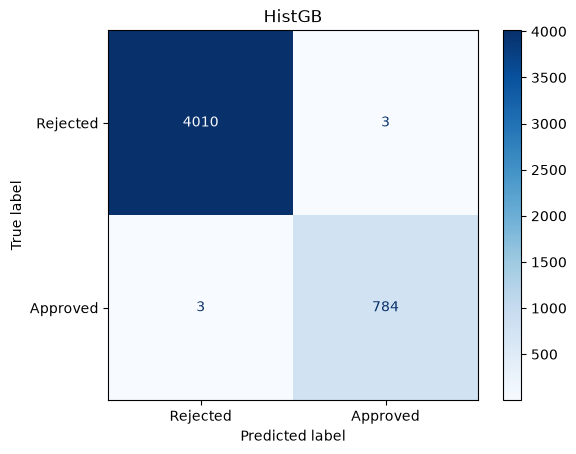

,threshold,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg + class_weight,0.5,0.637,0.948,0.762,0.974,0.881
Decision Tree (tuned),0.5,0.999,1.000,0.999,1.000,0.999
Decision Tree (simple),0.5,0.999,1.000,0.999,1.000,0.999
HistGB,0.5,0.996,0.996,0.996,1.000,1.000


In [19]:
def evaluate(name, pipe, X_te, y_te, threshold=0.5, show=True):
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    if show:
        print(f"===== {name} (threshold={threshold:.3f}) =====")
        print(classification_report(y_te, pred, target_names=["Rejected", "Approved"], digits=3))
        ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["Rejected", "Approved"], cmap="Blues")
        plt.title(name); save_fig("cm_" + slug(name)); plt.show()
    return {"model": name, "threshold": round(threshold, 3),
            "precision": precision_score(y_te, pred), "recall": recall_score(y_te, pred),
            "f1": f1_score(y_te, pred), "roc_auc": roc_auc_score(y_te, proba),
            "pr_auc": average_precision_score(y_te, proba)}

lr_model = build(LR(class_weight="balanced"), FS).fit(X_train, y_train)
hgb_model = build(HGB(), FS).fit(X_train, y_train)

finalists = {
    "LogReg + class_weight": lr_model,
    "Decision Tree (tuned)": gs.best_estimator_,          # GridSearchCV already refit it on all training data
    "Decision Tree (simple)": simple_tree,
    "HistGB": hgb_model,
}
test_rows = [evaluate(name, pipe, X_test, y_test) for name, pipe in finalists.items()]
pd.DataFrame(test_rows).set_index("model").round(3)

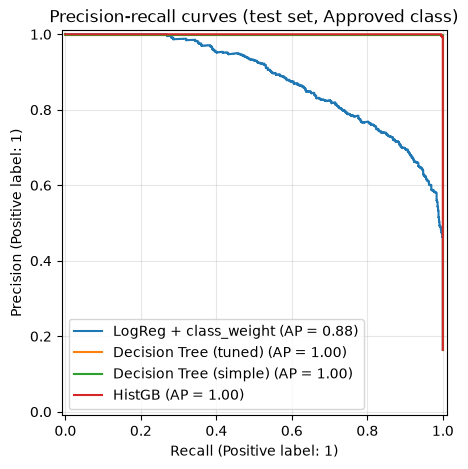

In [20]:
# Precision-recall curves on the test set: the whole trade-off, not just one threshold
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, pipe in finalists.items():
    PrecisionRecallDisplay.from_predictions(y_test, pipe.predict_proba(X_test)[:, 1], name=name, ax=ax)
ax.set_title("Precision-recall curves (test set, Approved class)"); ax.grid(alpha=0.3)
save_fig("pr_curves_test"); plt.show()

In [21]:
# Do the models rediscover the eligibility rules from the TRAINING data alone?
pre = simple_tree.named_steps["prep"]
scaler = pre.named_transformers_["num"].named_steps["sc"]
tree_ = simple_tree.named_steps["model"].tree_
feat_names = list(pre.get_feature_names_out())

rows = []
for node in range(tree_.node_count):
    f = tree_.feature[node]
    if f >= 0 and feat_names[f].startswith("num__"):
        col = feat_names[f][len("num__"):]
        j = FS["num"].index(col)
        rows.append((col, tree_.threshold[node] * scaler.scale_[j] + scaler.mean_[j]))

learned = pd.DataFrame(rows, columns=["feature", "threshold"])
print("Thresholds learned by the simple tree (original units):")
print(learned.groupby("feature")["threshold"].agg(lambda s: sorted(round(v, 3) for v in s)).to_string())
print("\nRules found in EDA: credit_score > 550 | dti_ratio <= 50 | loan_to_income <= 0.6 | employed")

Thresholds learned by the simple tree (original units):
feature
credit_score      [550.5]
dti_ratio         [50.02]
loan_to_income      [0.6]

Rules found in EDA: credit_score > 550 | dti_ratio <= 50 | loan_to_income <= 0.6 | employed


## 8. Decision threshold tuning

The default 0.5 cutoff is arbitrary. For a bank, **approving an application that should be rejected is usually the costly mistake**, so we care about the *precision* of the Approved class and then want as much recall as that allows.

Threshold tuning needs **smooth probabilities**, so it is applied to gradient boosting. (A fully grown decision tree outputs almost only 0 or 1, so thresholds are meaningless there.) The threshold is chosen from **out-of-fold predictions on the training data**, never from the test set.

In [22]:
threshold_model = build(HGB(), FS)
oof_proba = cross_val_predict(threshold_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)

# What does each precision target cost in recall? (a table you can show a business stakeholder)
tradeoff = []
for tp in [0.90, 0.95, 0.98, 0.99]:
    ok = prec[:-1] >= tp
    if ok.any():
        i = np.argmax(rec[:-1][ok])
        tradeoff.append({"target_precision": tp, "threshold": round(float(thr[ok][i]), 3), "oof_recall": round(float(rec[:-1][ok][i]), 3)})
    else:
        tradeoff.append({"target_precision": tp, "threshold": None, "oof_recall": None})
print(pd.DataFrame(tradeoff).to_string(index=False))

 target_precision  threshold  oof_recall
             0.90      0.000         1.0
             0.95      0.000         1.0
             0.98      0.000         1.0
             0.99      0.001         1.0


Plateau of equally good thresholds: 0.0002 to 0.0010
Chosen threshold: 0.001  (target precision >= 0.98)


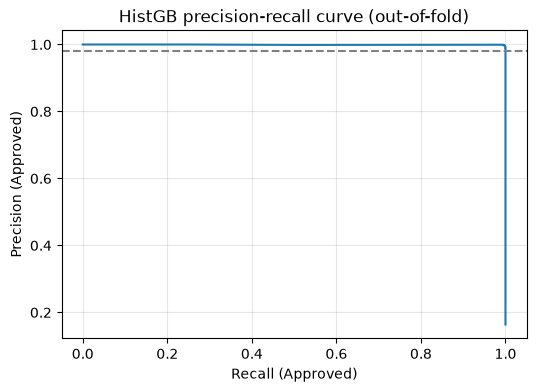

===== HistGB, tuned threshold (threshold=0.001) =====
              precision    recall  f1-score   support

    Rejected      1.000     0.999     0.999      4013
    Approved      0.992     1.000     0.996       787

    accuracy                          0.999      4800
   macro avg      0.996     0.999     0.998      4800
weighted avg      0.999     0.999     0.999      4800



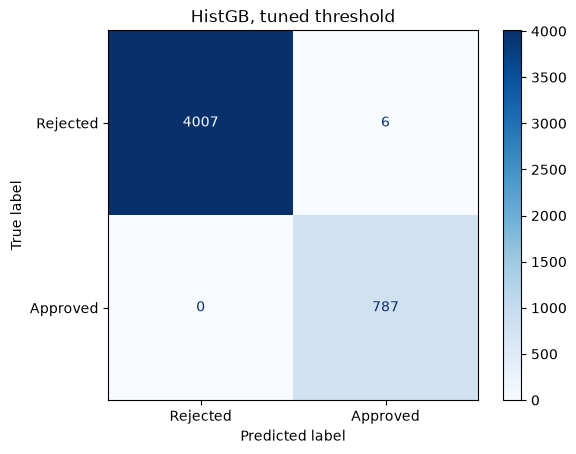

,threshold,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
LogReg + class_weight,0.500,0.637,0.948,0.762,0.974,0.881
Decision Tree (tuned),0.500,0.999,1.000,0.999,1.000,0.999
Decision Tree (simple),0.500,0.999,1.000,0.999,1.000,0.999
HistGB,0.500,0.996,0.996,0.996,1.000,1.000
"HistGB, tuned threshold",0.001,0.992,1.000,0.996,1.000,1.000


In [23]:
TARGET_PRECISION = 0.98    # <-- business decision: adjust and discuss

ok = prec[:-1] >= TARGET_PRECISION
if ok.any():
    rec_ok, thr_ok = rec[:-1][ok], thr[ok]
    plateau = thr_ok[rec_ok >= rec_ok.max() - 1e-9]          # every threshold that achieves the best recall
    best_thr = float((plateau.min() + plateau.max()) / 2)    # midpoint of that plateau: robust, not an edge
    print(f"Plateau of equally good thresholds: {plateau.min():.4f} to {plateau.max():.4f}")
else:
    best_thr = 0.5
    print("Target precision not reachable on out-of-fold data; falling back to 0.5")
print(f"Chosen threshold: {best_thr:.3f}  (target precision >= {TARGET_PRECISION})")

plt.figure(figsize=(6, 4))
plt.plot(rec, prec); plt.axhline(TARGET_PRECISION, ls="--", c="gray")
plt.xlabel("Recall (Approved)"); plt.ylabel("Precision (Approved)"); plt.title("HistGB precision-recall curve (out-of-fold)")
plt.grid(alpha=0.3); save_fig("pr_curve_oof_histgb"); plt.show()

threshold_model.fit(X_train, y_train)
tuned_row = evaluate("HistGB, tuned threshold", threshold_model, X_test, y_test, threshold=best_thr)
final_table = pd.DataFrame(test_rows + [tuned_row]).set_index("model").round(3)
final_table

## 9. Error analysis, feature importance and a stress test

### 9a. Where does the tuned tree go wrong?
Looking at the misclassified applications often reveals more than another metric.

In [24]:
tree_pred = gs.best_estimator_.predict(X_test)
wrong = tree_pred != y_test
errors = X_test.assign(y_true=y_test, y_pred=tree_pred)[wrong]
false_approvals = errors[errors["y_pred"] == 1]
missed_approvals = errors[errors["y_pred"] == 0]
print(f"{len(false_approvals)} false approvals (costly) and {len(missed_approvals)} missed approvals, out of {len(y_test)} test applications")

profile = pd.concat({"all test": X_test[BASE_NUM].mean(),
                     "false approvals": false_approvals[BASE_NUM].mean(),
                     "missed approvals": missed_approvals[BASE_NUM].mean()}, axis=1).round(2)
print("\nAverage profile:")
print(profile)
print("\nEmployment status of false approvals:\n", false_approvals["employment_status"].value_counts().to_string())

1 false approvals (costly) and 0 missed approvals, out of 4800 test applications

Average profile:
               all test  false approvals  missed approvals
income        110458.57         72554.00               NaN
credit_score     577.67           811.00               NaN
loan_amount    44928.60         32479.00               NaN
dti_ratio         34.71            50.01               NaN

Employment status of false approvals:
 employment_status
employed    1


### 9b. What drives the decisions?
Two complementary views. Impurity-based importance (built into trees) is fast but can be biased. **Permutation importance** (the drop in F1 when one feature is shuffled on the test set) is model-agnostic and more trustworthy. It is computed here for the tuned tree, for gradient boosting, and for logistic regression, so you can see where the models agree.

Tuned tree: impurity importance, top 10
num__credit_score                    0.329
num__loan_to_income                  0.238
num__dti_ratio                       0.235
cat__employment_status_unemployed    0.198
num__income                          0.000
num__loan_amount                     0.000
cat__employment_status_employed      0.000


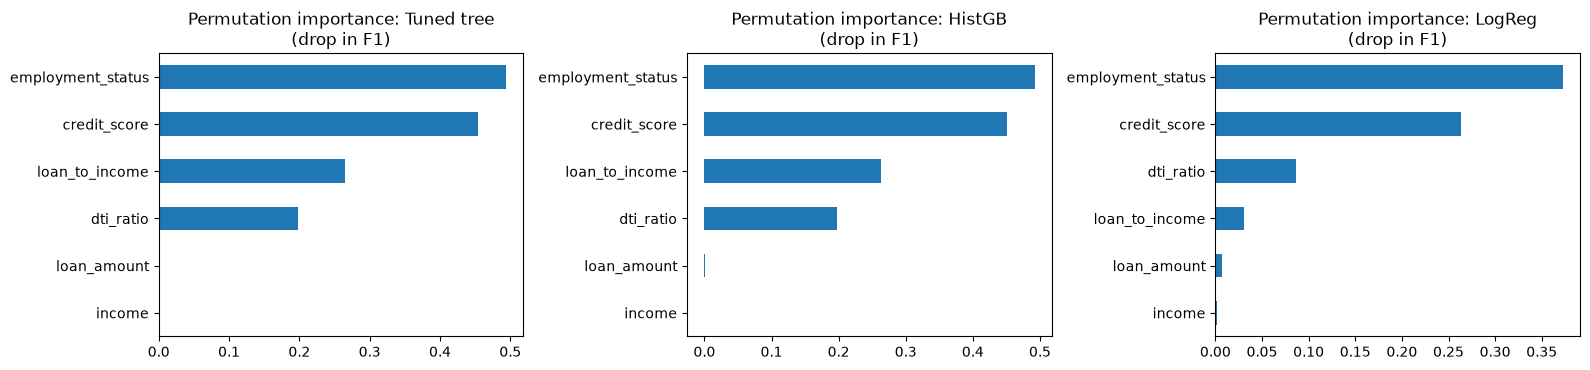

In [25]:
best_tree = gs.best_estimator_
names = best_tree.named_steps["prep"].get_feature_names_out()
tree_imp = pd.Series(best_tree.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print("Tuned tree: impurity importance, top 10")
print(tree_imp.head(10).round(3).to_string())

def perm_importance(model):
    r = permutation_importance(model, X_test[USED_COLS], y_test, scoring="f1", n_repeats=10,
                               random_state=RANDOM_STATE, n_jobs=-1)
    return pd.Series(r.importances_mean, index=USED_COLS).sort_values()

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharex=False)
for ax, (title, model) in zip(axes, [("Tuned tree", gs.best_estimator_),
                                     ("HistGB", hgb_model),
                                     ("LogReg", lr_model)]):
    perm_importance(model).plot(kind="barh", ax=ax)
    ax.set_title(f"Permutation importance: {title}\n(drop in F1)")
plt.tight_layout(); save_fig("permutation_importance"); plt.show()

### 9c. Stress test: what if the dominant feature disappears?
If one feature (credit score) carries most of the signal, the problem may look easier than it is. Re-training gradient boosting without it shows how much the other features can compensate.

In [26]:
fs_no_credit = {**FS, "num": [c for c in FS["num"] if c != "credit_score"]}

rows = []
for label, fs in {"with credit_score": FS, "without credit_score": fs_no_credit}.items():
    s = cross_validate(build(HGB(), fs), X_train, y_train, cv=cv, n_jobs=-1,
                       scoring={"precision": "precision", "recall": "recall", "f1": "f1", "pr_auc": "average_precision"})
    rows.append({"HistGB": label, **{k: s[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "pr_auc"]}})
stress = pd.DataFrame(rows).set_index("HistGB").round(3)
stress

,precision,recall,f1,pr_auc
HistGB,,,,
with credit_score,0.997,0.997,0.997,0.999
without credit_score,0.540,0.683,0.603,0.544


## 10. Save results

Tables are written to `results/` so the README and your submission can reference real files.

In [27]:
cv_table.to_csv(RES_DIR / "cv_comparison.csv")
final_table.to_csv(RES_DIR / "test_results.csv")
ablation.to_csv(RES_DIR / "feature_ablation.csv", index=False)
stress.to_csv(RES_DIR / "stress_test.csv")
print("Saved:", sorted(p.name for p in RES_DIR.iterdir()))
print("Figures:", sorted(p.name for p in IMG_DIR.iterdir()))

Saved: ['cv_comparison.csv', 'feature_ablation.csv', 'stress_test.csv', 'test_results.csv']
Figures: ['cm_decision_tree_simple.png', 'cm_decision_tree_tuned.png', 'cm_histgb.png', 'cm_histgb_tuned_threshold.png', 'cm_logreg_class_weight.png', 'eda_approval_rate_by_band.png', 'eda_histograms.png', 'eda_target_and_correlation.png', 'permutation_importance.png', 'pr_curve_oof_histgb.png', 'pr_curves_test.png', 'tree_depth_vs_f1.png']


In [28]:
print("Missing values (total):", int(X.isna().sum().sum()), "| DTI > 100%:", int((df.dti_ratio > 100).sum()))
print("Selected feature set  :", FEATURE_SET)
print("Best tree params      :", gs.best_params_, "| CV F1:", round(gs.best_score_, 4))
m = simple_tree.named_steps["model"]
print("Simple tree           :", m.criterion, "| depth:", m.max_depth, "| min_samples_leaf:", m.min_samples_leaf)
print("Chosen threshold      :", round(best_thr, 4))
print("\nTrade-off table:\n", pd.DataFrame(tradeoff).to_string(index=False))
print("\nThresholds learned by the simple tree:")
print(learned.groupby("feature")["threshold"].agg(lambda s: sorted(round(v, 3) for v in s)).to_string())

for f in ["feature_ablation.csv", "cv_comparison.csv", "test_results.csv", "stress_test.csv"]:
    print(f"\n===== {f} =====")
    print(pd.read_csv(RES_DIR / f).to_string(index=False))

Missing values (total): 0 | DTI > 100%: 1255
Selected feature set  : tabular + loan_to_income
Best tree params      : {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_leaf': 1} | CV F1: 0.9998
Simple tree           : gini | depth: 4 | min_samples_leaf: 20
Chosen threshold      : 0.0006

Trade-off table:
  target_precision  threshold  oof_recall
             0.90      0.000         1.0
             0.95      0.000         1.0
             0.98      0.000         1.0
             0.99      0.001         1.0

Thresholds learned by the simple tree:
feature
credit_score      [550.5]
dti_ratio         [50.02]
loan_to_income      [0.6]

===== feature_ablation.csv =====
             feature_set             model       f1   pr_auc  roc_auc
                 tabular LogReg (balanced) 0.771449 0.885271 0.975946
                 tabular    Tree (depth 8) 0.971926 0.988058 0.997344
tabular + loan_to_income LogReg (balanced) 0.780840 0.890837 0.976980
tabular + loan_to_income  

## 11. Conclusions and limitations (write your own version)

**Dataset:** 24,000 applications, about 16.4% approved. Selected feature set: ... (and why, from the ablation).

**Best model:** ..., with precision ..., recall ..., F1 ... for the Approved class on the test set. The simplest near-equivalent tree uses depth ... and reaches F1 ....

**Logistic Regression vs Decision Tree vs Gradient Boosting:** ... (what the gap says about linear vs threshold-like structure).

**Did imbalance handling help?** Class weights / SMOTE: ... Threshold tuning at precision >= ...: recall became ....

**What drives decisions:** ... (agreement and disagreement between the three importance views). Stress test without credit score: F1 ....

**Limitations**
- The feature distributions (uniform income and credit score) strongly suggest **synthetic data**, and near-deterministic labels explain the very high tree scores. Real lending data is noisier, so these scores will not transfer.
- DTI ratios above 100% are unusual and were left as-is; in practice they would be investigated.
- The free-text purpose adds ... (state the ablation result).
- **Fairness:** employment status and other attributes can proxy for protected characteristics. A real credit model needs a bias audit and legal review, which this analysis does not do.
- The decision threshold should come from real business costs (cost of a bad approval vs a lost good customer), not a fixed precision target.
- One random split plus 5-fold CV on the training set; no external or time-based validation.

**Next steps:** calibrate probabilities, set a cost-based threshold, test on out-of-time data, check performance across subgroups, then package the winning pipeline behind an API (the MLOps task).